# 02b IMU extra checks

Extra checks that follow up the IMU audit in notebook 02.

## Step 1a - setup and tables

Finds the project folder, loads the three report tables and leaves out the stub files.

In [1]:
import json
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from tqdm import tqdm

pd.set_option("display.width", 200)

DEVICES = ["head", "left", "right"]
CHUNK_S = 180
GRAV = 9.81

# project root is the parent of the working directory
PROJECT_ROOT = Path.cwd().parent
config_path = PROJECT_ROOT / "configs" / "config.yaml"
if not config_path.exists():
    raise FileNotFoundError(
        f"configs/config.yaml not found under {PROJECT_ROOT}. "
        "Open this notebook from the notebooks folder of the project."
    )
with open(config_path, "r", encoding="utf-8") as fh:
    cfg = yaml.safe_load(fh)

INTERIM = PROJECT_ROOT / "interim"
REPORTS = PROJECT_ROOT / "reports"
REPORTS.mkdir(parents=True, exist_ok=True)

def show(df, n=50):
    print(df.head(n).to_string(index=False))
    if len(df) > n:
        print(f"... {len(df) - n} more rows not shown")

table_paths = {
    "summary": REPORTS / "02_imu_file_summary.csv",
    "seams": REPORTS / "02_seams.csv",
    "triplets": REPORTS / "02_triplet_offsets.csv",
}
for p in table_paths.values():
    if not p.exists():
        raise FileNotFoundError(f"{p} not found, run notebook 02 first")

summary = pd.read_csv(table_paths["summary"])
seams = pd.read_csv(table_paths["seams"])
triplets = pd.read_csv(table_paths["triplets"])

# stub files are left out everywhere
used = summary[summary["status"] != "stub"].copy()
used["dev_order"] = used["device"].map({d: i for i, d in enumerate(DEVICES)})
used = used.sort_values(["dev_order", "clip_no"]).reset_index(drop=True)
used["rank"] = used.groupby("device").cumcount() + 1
rec_s = {d: float(used.loc[used["device"] == d, "duration_s"].sum()) for d in DEVICES}

print("summary rows:", len(summary), " seams rows:", len(seams), " triplet rows:", len(triplets))
print("files used:", len(used), " stubs left out:", int((summary["status"] == "stub").sum()))

summary rows: 47  seams rows: 42  triplet rows: 15
files used: 45  stubs left out: 2


## Step 1b - arrays

Reads the npz arrays of all used files into a dict keyed by base name and counts the files per device.

In [2]:
npz_dir = INTERIM / "imu"
first_name = used["base_name"].iloc[0]
with np.load(npz_dir / f"{first_name}.npz") as z:
    keys = list(z.files)
print("keys of the first file:", keys)
if sorted(keys) != ["acc", "gyro", "t_us"]:
    raise ValueError(f"unexpected keys {keys}, expected t_us, acc and gyro")

data = {}
for name in tqdm(used["base_name"], desc="loading", mininterval=1.0):
    p = npz_dir / f"{name}.npz"
    if not p.exists():
        raise FileNotFoundError(f"{p} not found")
    with np.load(p) as z:
        data[name] = {"t_us": z["t_us"].astype(np.int64),
                      "acc": z["acc"].astype(np.float64),
                      "gyro": z["gyro"].astype(np.float64)}

for d in DEVICES:
    sub = used[used["device"] == d]
    n_rows = sum(len(data[n]["t_us"]) for n in sub["base_name"])
    print(f"{d}: {len(sub)} files, {n_rows} rows, {rec_s[d] / 60:.1f} min")

keys of the first file: ['t_us', 'acc', 'gyro']


loading: 100%|██████████| 45/45 [00:01<00:00, 26.61it/s]

head: 15 files, 77371 rows, 43.0 min
left: 15 files, 76254 rows, 42.4 min
right: 15 files, 76882 rows, 42.7 min


## Step 2a - long intervals

Collects every interval above 50 ms. Intervals up to 80 ms are called typical and the rest stall.

In [3]:
def collect(test):
    # test gets the dt array in microseconds and returns a boolean mask
    parts = []
    for r in used.itertuples():
        t = data[r.base_name]["t_us"]
        if len(t) < 2:
            continue
        dt = np.diff(t)
        idx = np.where(test(dt))[0] + 1      # index of the later sample
        if len(idx):
            parts.append(pd.DataFrame({
                "device": r.device, "file": r.base_name, "row_index": idx,
                "t_us": t[idx], "dt_ms": dt[idx - 1] / 1000.0}))
    if not parts:
        return pd.DataFrame(columns=["device", "file", "row_index", "t_us", "dt_ms"])
    return pd.concat(parts, ignore_index=True)

long_df = collect(lambda dt: dt > 50_000)
long_df["kind"] = np.where(long_df["dt_ms"] >= 80, "stall", "typical")
typ = long_df[long_df["kind"] == "typical"].copy()

tab = []
for d in DEVICES:
    files = used.loc[used["device"] == d, "base_name"].tolist()
    per_file = typ[typ["device"] == d].groupby("file").size().reindex(files, fill_value=0)
    n_typ = int(per_file.sum())
    tab.append({"device": d, "files": len(files), "typical": n_typ,
                "mean_per_file": per_file.mean(), "max_per_file": int(per_file.max()),
                "per_180s": n_typ / rec_s[d] * CHUNK_S,
                "stall": int(((long_df["device"] == d) & (long_df["kind"] == "stall")).sum())})
show(pd.DataFrame(tab).round(3))

long_df.to_csv(REPORTS / "02b_long_intervals.csv", index=False)
print("saved 02b_long_intervals.csv with", len(long_df), "events")

device  files  typical  mean_per_file  max_per_file  per_180s  stall
  head     15       36          2.400             3     2.513      2
  left     15       37          2.467             5     2.620      1
 right     15       40          2.667             5     2.809      0
saved 02b_long_intervals.csv with 116 events


## Step 2b - period test

For periods from 60 to 90 s it measures how well the typical events line up in phase. A shuffled control with random times is used for comparison.

In [4]:
PERIODS = np.round(np.arange(6000, 9001) / 100.0, 2)    # 60 to 90 s in 0.01 s steps
N_CONTROL = 200
rng = np.random.default_rng(1)

def resultant(times_s):
    # resultant length for every candidate period, in blocks to save memory
    out = []
    for i in range(0, len(PERIODS), 500):
        p = PERIODS[i:i + 500]
        ang = 2 * np.pi * times_s[None, :] / p[:, None]
        out.append(np.abs(np.exp(1j * ang).mean(axis=1)))
    return np.concatenate(out)

def best_of(times_s):
    r = resultant(times_s)
    k = int(np.argmax(r))
    return float(PERIODS[k]), float(r[k])

period_res = {}
for name in DEVICES + ["pooled"]:
    sel = typ if name == "pooled" else typ[typ["device"] == name]
    grp = used if name == "pooled" else used[used["device"] == name]
    ts = sel["t_us"].to_numpy(dtype=np.float64) / 1e6
    lo = float(grp["first_t_us"].min()) / 1e6
    hi = float(grp["last_t_us"].max()) / 1e6
    res = {"n_events": int(len(ts)), "best_period_s": None, "R": None,
           "control_median_R": None, "control_max_R": None, "clearly_above_control": None}
    if len(ts) >= 3:
        bp, br = best_of(ts)
        # control: same number of random times, best R over the same periods
        ctrl = np.array([best_of(rng.uniform(lo, hi, size=len(ts)))[1] for _ in range(N_CONTROL)])
        res.update({"best_period_s": bp, "R": br, "control_median_R": float(np.median(ctrl)),
                    "control_max_R": float(ctrl.max()), "clearly_above_control": bool(br > ctrl.max())})
        verdict = "R is clearly above the control" if res["clearly_above_control"] else "R is not clearly above the control"
        print(f"{name}: {len(ts)} events, best P = {bp:.2f} s, R = {br:.3f}, "
              f"control median R = {res['control_median_R']:.3f} (max {res['control_max_R']:.3f}) -> {verdict}")
    else:
        print(f"{name}: {len(ts)} events, too few for the test")
    period_res[name] = res

head: 36 events, best P = 73.30 s, R = 0.999, control median R = 0.321 (max 0.568) -> R is clearly above the control
left: 37 events, best P = 73.34 s, R = 0.982, control median R = 0.321 (max 0.503) -> R is clearly above the control
right: 40 events, best P = 73.32 s, R = 0.950, control median R = 0.316 (max 0.542) -> R is clearly above the control
pooled: 113 events, best P = 73.31 s, R = 0.967, control median R = 0.181 (max 0.263) -> R is clearly above the control


## Step 3 - shared events

Counts events of one device that have an event of another device within 100 ms and compares with the number expected by chance. Done for the long intervals and for the zero length intervals.

In [5]:
WINDOW_US = 100_000
zero_df = collect(lambda dt: dt == 0)
zero_df["kind"] = "zero"
match_cols = ["event_type", "device_a", "device_b", "file_a", "row_a", "t_us_a", "dt_ms_a",
              "file_b", "row_b", "t_us_b", "dt_ms_b", "diff_ms"]

def nearest_match(ea, eb, etype):
    # nearest event of eb within the window for every event of ea
    if len(ea) == 0 or len(eb) == 0:
        return pd.DataFrame(columns=match_cols)
    eb = eb.sort_values("t_us").reset_index(drop=True)
    ta = ea["t_us"].to_numpy()
    tb = eb["t_us"].to_numpy()
    pos = np.searchsorted(tb, ta)
    left = np.clip(pos - 1, 0, len(tb) - 1)
    right = np.clip(pos, 0, len(tb) - 1)
    pick = np.where(np.abs(ta - tb[left]) <= np.abs(ta - tb[right]), left, right)
    ok = np.where(np.abs(tb[pick] - ta) <= WINDOW_US)[0]
    a = ea.iloc[ok].reset_index(drop=True)
    b = eb.iloc[pick[ok]].reset_index(drop=True)
    return pd.DataFrame({
        "event_type": etype, "device_a": a["device"], "device_b": b["device"],
        "file_a": a["file"], "row_a": a["row_index"], "t_us_a": a["t_us"], "dt_ms_a": a["dt_ms"],
        "file_b": b["file"], "row_b": b["row_index"], "t_us_b": b["t_us"], "dt_ms_b": b["dt_ms"],
        "diff_ms": (b["t_us"] - a["t_us"]) / 1000.0})

def swap_ab(df):
    out = df.rename(columns=lambda c: c[:-1] + "b" if c.endswith("_a") else (c[:-1] + "a" if c.endswith("_b") else c))
    out["diff_ms"] = -out["diff_ms"]
    return out

pairs = [("head", "left"), ("head", "right"), ("left", "right")]
shared_rows, matched_parts = [], []
for etype, edf in (("long", long_df), ("zero", zero_df)):
    for a, b in pairs:
        ea = edf[edf["device"] == a]
        eb = edf[edf["device"] == b]
        m_ab = nearest_match(ea, eb, etype)
        m_ba = nearest_match(eb, ea, etype)
        # chance: events of one device times event rate of the other times the 0.2 s window
        exp_ab = len(ea) * (len(eb) / rec_s[b]) * 0.2
        exp_ba = len(eb) * (len(ea) / rec_s[a]) * 0.2
        shared_rows.append({"type": etype, "pair": f"{a}-{b}", "n_first": len(ea), "n_second": len(eb),
                            "first_with_second": len(m_ab), "expected_1": exp_ab,
                            "second_with_first": len(m_ba), "expected_2": exp_ba})
        for m in (m_ab, swap_ab(m_ba)):
            if len(m):
                matched_parts.append(m)

shared_tab = pd.DataFrame(shared_rows)
show(shared_tab.round(3))

if matched_parts:
    shared = pd.concat(matched_parts, ignore_index=True)
    shared = shared.drop_duplicates(subset=["event_type", "file_a", "row_a", "file_b", "row_b"])
else:
    shared = pd.DataFrame(columns=match_cols)
shared.to_csv(REPORTS / "02b_shared_events.csv", index=False)
print("saved 02b_shared_events.csv with", len(shared), "matched events")

type       pair  n_first  n_second  first_with_second  expected_1  second_with_first  expected_2
long  head-left       38        38                  0       0.114                  0       0.112
long head-right       38        40                  2       0.119                  3       0.118
long left-right       38        40                 25       0.119                 26       0.120
zero  head-left        4         1                  0       0.000                  0       0.000
zero head-right        4         1                  2       0.000                  1       0.000
zero left-right        1         1                  0       0.000                  0       0.000
saved 02b_shared_events.csv with 31 matched events


## Step 4 - row anomalies

Lists rows with dt = 0, rows where acc and gyro are all zero and rows whose acc equals the previous row.

In [6]:
anom_kinds = ["dt_zero", "all_zero", "acc_repeat"]
anom_parts = []
total_rows = 0
for r in used.itertuples():
    t = data[r.base_name]["t_us"]
    acc = data[r.base_name]["acc"]
    gyro = data[r.base_name]["gyro"]
    n = len(t)
    total_rows += n
    if n == 0:
        continue
    dt = np.diff(t)
    before = np.full(n, np.nan)
    after = np.full(n, np.nan)
    before[1:] = dt / 1000.0
    after[:-1] = dt / 1000.0
    dt_zero = np.zeros(n, dtype=bool)
    dt_zero[1:] = dt == 0
    same_prev = np.zeros(n, dtype=bool)
    same_prev[1:] = np.all(acc[1:] == acc[:-1], axis=1)
    same_next = np.zeros(n, dtype=bool)
    same_next[:-1] = same_prev[1:]
    all_zero = np.all(acc == 0, axis=1) & np.all(gyro == 0, axis=1)
    for kind, mask in (("dt_zero", dt_zero), ("all_zero", all_zero), ("acc_repeat", same_prev)):
        idx = np.where(mask)[0]
        if len(idx):
            anom_parts.append(pd.DataFrame({
                "kind": kind, "device": r.device, "file": r.base_name, "row_index": idx,
                "t_us": t[idx], "dt_before_ms": before[idx], "dt_after_ms": after[idx],
                "acc_repeats_prev": same_prev[idx], "acc_repeats_next": same_next[idx]}))

anom_cols = ["kind", "device", "file", "row_index", "t_us", "dt_before_ms", "dt_after_ms",
             "acc_repeats_prev", "acc_repeats_next"]
anom_df = pd.concat(anom_parts, ignore_index=True) if anom_parts else pd.DataFrame(columns=anom_cols)
anom_counts = {k: int((anom_df["kind"] == k).sum()) for k in anom_kinds}

print("used rows in total:", total_rows)
for k in anom_kinds:
    print(f"{k}: {anom_counts[k]} rows, {100.0 * anom_counts[k] / total_rows:.4f} % of used rows")

for k in anom_kinds:
    sub = anom_df[anom_df["kind"] == k]
    print()
    print(k)
    if len(sub):
        show(sub.drop(columns="kind").round(3))
    else:
        print("none")

anom_df.to_csv(REPORTS / "02b_row_anomalies.csv", index=False)
print()
print("saved 02b_row_anomalies.csv")

used rows in total: 230507
dt_zero: 6 rows, 0.0026 % of used rows
all_zero: 2 rows, 0.0009 % of used rows
acc_repeat: 18 rows, 0.0078 % of used rows

dt_zero
device          file  row_index       t_us  dt_before_ms  dt_after_ms  acc_repeats_prev  acc_repeats_next
  head a45140-H-0049         11 2348147768           0.0        0.000              True              True
  head a45140-H-0049         12 2348147768           0.0      124.172              True             False
  head a45140-H-0050         10 2528151685           0.0        0.000              True              True
  head a45140-H-0050         11 2528151685           0.0      101.828              True             False
  left a60617-H-0032        624 2188544788           0.0       89.342              True             False
 right a59879-H-0039         12 2348193771           0.0       72.044              True             False

all_zero
device          file  row_index       t_us  dt_before_ms  dt_after_ms  acc_repeats_prev  a

## Step 5 - drift fit

Fits straight lines to the start grid error in the seams table and to the triplet start offsets, and gives the slopes in ppm of 180 s.

In [7]:
PPM = 1e6 / (CHUNK_S * 1000.0)     # ms per chunk to ppm of 180 s
N_CHUNKS = 13                      # 13 chunks = 2340 s

def linfit(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    n = len(x)
    if n < 3:
        return n, np.nan, np.nan
    xm = x.mean()
    sxx = ((x - xm) ** 2).sum()
    slope = ((x - xm) * (y - y.mean())).sum() / sxx
    resid = y - (y.mean() + slope * (x - xm))
    se = np.sqrt((resid ** 2).sum() / (n - 2) / sxx)
    return n, float(slope), float(se)

fit_rows = []
def add_fit(source, series, ranks, x, y):
    n, slope, se = linfit(x, y)
    fit_rows.append({"source": source, "series": series, "ranks": ranks, "n": n,
                     "slope_ms_per_chunk": slope, "se_ms_per_chunk": se,
                     "slope_ppm": slope * PPM, "se_ppm": se * PPM,
                     "change_13_chunks_ms": slope * N_CHUNKS, "se_change_13_chunks_ms": se * N_CHUNKS})

for d in DEVICES:
    s = seams[seams["device"] == d]
    add_fit("seams", d, "all", s["chunk_k"], s["start_grid_error_ms"])

for lo in (1, 2):
    sub = triplets[triplets["rank"] >= lo]
    for side in ("left", "right"):
        add_fit("triplets", side, f"{lo}-{int(triplets['rank'].max())}", sub["rank"], sub[f"start_offset_{side}_ms"])

fit_df = pd.DataFrame(fit_rows)

print("seams, start grid error against chunk_k")
for r in fit_df[fit_df["source"] == "seams"].itertuples():
    print(f"{r.series}: slope {r.slope_ms_per_chunk:.3f} +- {r.se_ms_per_chunk:.3f} ms per chunk"
          f" = {r.slope_ppm:.1f} +- {r.se_ppm:.1f} ppm (n = {r.n})")
print()
print("triplets, start offset against rank")
for r in fit_df[fit_df["source"] == "triplets"].itertuples():
    print(f"{r.series} ranks {r.ranks}: slope {r.slope_ppm:.1f} +- {r.se_ppm:.1f} ppm,"
          f" change over 13 chunks (2340 s) {r.change_13_chunks_ms:.1f} ms (n = {r.n})")
print()
print("note: offsets are only known to about one frame (33 ms) because the timestamps are jittered.")

fit_df.to_csv(REPORTS / "02b_drift_fit.csv", index=False)

seams, start grid error against chunk_k
head: slope 0.398 +- 0.624 ms per chunk = 2.2 +- 3.5 ppm (n = 14)
left: slope 2.770 +- 0.988 ms per chunk = 15.4 +- 5.5 ppm (n = 14)
right: slope 6.721 +- 1.042 ms per chunk = 37.3 +- 5.8 ppm (n = 14)

triplets, start offset against rank
left ranks 1-15: slope 9.9 +- 3.7 ppm, change over 13 chunks (2340 s) 23.2 ms (n = 15)
right ranks 1-15: slope 28.4 +- 5.3 ppm, change over 13 chunks (2340 s) 66.5 ms (n = 15)
left ranks 2-15: slope 13.2 +- 3.6 ppm, change over 13 chunks (2340 s) 30.8 ms (n = 14)
right ranks 2-15: slope 35.1 +- 4.1 ppm, change over 13 chunks (2340 s) 82.2 ms (n = 14)

note: offsets are only known to about one frame (33 ms) because the timestamps are jittered.


## Step 6a - orientation and stillness

Per file: still fraction, median gyro norm, rest norm and how well the rest direction matches the median of the device.

In [8]:
dir_cols = ["rest_dir_x", "rest_dir_y", "rest_dir_z"]
still, gmed = [], []
for name in used["base_name"]:
    gn = np.linalg.norm(data[name]["gyro"], axis=1)
    still.append(float(np.mean(gn < 0.1)) if len(gn) else np.nan)
    gmed.append(float(np.median(gn)) if len(gn) else np.nan)

orient = used[["device", "rank", "clip_no", "base_name", "rows", "rest_norm"] + dir_cols].copy()
orient["still_fraction"] = still
orient["gyro_norm_median"] = gmed
orient["cos_to_median_dir"] = np.nan
for d in DEVICES:
    sel = (orient["device"] == d) & orient[dir_cols].notna().all(axis=1)
    if not sel.any():
        continue
    med = np.median(orient.loc[sel, dir_cols].to_numpy(), axis=0)
    med = med / np.linalg.norm(med)
    orient.loc[sel, "cos_to_median_dir"] = orient.loc[sel, dir_cols].to_numpy() @ med

show_cols = ["rank", "clip_no", "rows", "still_fraction", "gyro_norm_median", "rest_norm", "cos_to_median_dir"]
for d in DEVICES:
    print(d)
    show(orient[orient["device"] == d][show_cols].round(3))
    print()

orient.to_csv(REPORTS / "02b_orientation.csv", index=False)
print("saved 02b_orientation.csv")

head
 rank  clip_no  rows  still_fraction  gyro_norm_median  rest_norm  cos_to_median_dir
    1       36  5400           0.362             0.157     11.050              0.907
    2       37  5400           0.354             0.138     11.076              0.998
    3       38  5400           0.511             0.098     11.062              0.995
    4       39  5400           0.623             0.085     11.014              0.976
    5       40  5400           0.589             0.091     11.018              0.983
    6       41  5400           0.346             0.151     11.073              0.999
    7       42  5400           0.464             0.106     11.093              0.999
    8       43  5400           0.330             0.142     11.068              0.999
    9       44  5400           0.429             0.115     11.052              0.997
   10       45  5400           0.396             0.119     10.988              0.993
   11       46  5400           0.340             0.140     1

## Step 6b - head z axis offset

Compares the z part of the rest vector of the normal head chunks with the last head chunk.

In [9]:
head = orient[orient["device"] == "head"].sort_values("rank").copy()
head["rest_z"] = head["rest_norm"] * head["rest_dir_z"]
normal_z = head.loc[head["rank"].between(1, 14), "rest_z"].dropna()
last_z = head["rest_z"].iloc[-1] if len(head) else np.nan

head_est = {"z_normal": None, "z_last": None, "offset_z": None, "gain_z": None}
if len(normal_z) and np.isfinite(last_z):
    z_normal = float(normal_z.median())
    z_last = float(last_z)
    head_est["z_normal"], head_est["z_last"] = z_normal, z_last
    print(f"z_normal (median of head chunks 1 to 14): {z_normal:.3f}")
    print(f"z_last (last head chunk): {z_last:.3f}")
    if np.sign(z_normal) * np.sign(z_last) < 0:
        head_est["offset_z"] = (z_normal + z_last) / 2
        head_est["gain_z"] = (abs(z_normal) + abs(z_last)) / 2 / GRAV
        print(f"offset_z = {head_est['offset_z']:.3f}")
        print(f"gain_z = {head_est['gain_z']:.4f}")
    else:
        print("the signs do not differ, so no offset or gain is estimated")
    print("warning: this assumes the last chunk is a pure flip of the head device.")
else:
    print("not enough head chunks with a rest vector")

z_normal (median of head chunks 1 to 14): -10.753
z_last (last head chunk): 8.626
offset_z = -1.064
gain_z = 0.9877


## Step 7 - figure

Top: the long interval events of each device on the session clock. Bottom: the still fraction per chunk.

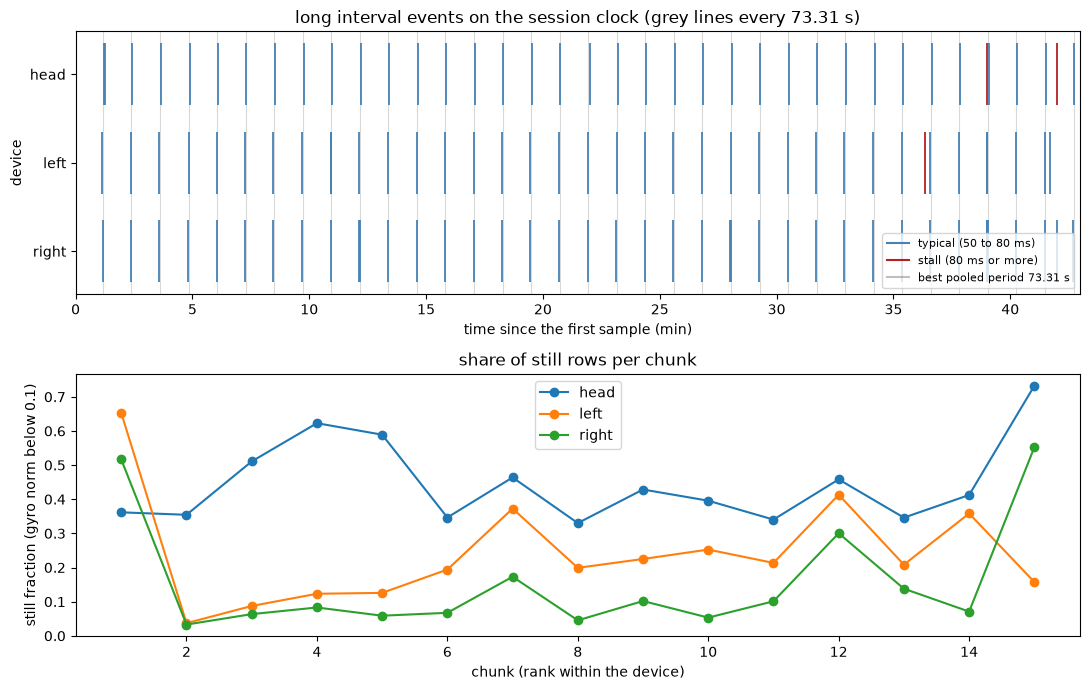

In [10]:
from matplotlib.lines import Line2D

t0 = float(used["first_t_us"].min())
x_end = (float(used["last_t_us"].max()) - t0) / 6e7
kind_color = {"typical": "steelblue", "stall": "firebrick"}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7))

# a: events as ticks, one row per device
for yi, d in enumerate(DEVICES):
    for kind, c in kind_color.items():
        sel = (long_df["device"] == d) & (long_df["kind"] == kind)
        x = (long_df.loc[sel, "t_us"].to_numpy(dtype=float) - t0) / 6e7
        ax1.vlines(x, yi - 0.35, yi + 0.35, color=c, linewidth=1.3)

handles = [Line2D([0], [0], color="steelblue", label="typical (50 to 80 ms)"),
           Line2D([0], [0], color="firebrick", label="stall (80 ms or more)")]
pp = period_res["pooled"]
title_a = "long interval events on the session clock"
if pp["best_period_s"] is not None:
    P_best = pp["best_period_s"]
    tt = typ["t_us"].to_numpy(dtype=float) / 1e6
    phi = np.angle(np.exp(2j * np.pi * tt / P_best).mean())
    t_lo = t0 / 1e6
    t_hi = float(used["last_t_us"].max()) / 1e6
    ks = np.arange(int(np.floor(t_lo / P_best)) - 1, int(np.ceil(t_hi / P_best)) + 2)
    for ln in (phi / (2 * np.pi) + ks) * P_best:
        xm = (ln - t_lo) / 60.0
        if 0 <= xm <= x_end:
            ax1.axvline(xm, color="gray", alpha=0.3, linewidth=0.8, zorder=0)
    handles.append(Line2D([0], [0], color="gray", alpha=0.5, label=f"best pooled period {P_best:.2f} s"))
    title_a += f" (grey lines every {P_best:.2f} s)"
ax1.set_yticks(range(len(DEVICES)))
ax1.set_yticklabels(DEVICES)
ax1.invert_yaxis()
ax1.set_xlim(0, x_end)
ax1.set_xlabel("time since the first sample (min)")
ax1.set_ylabel("device")
ax1.set_title(title_a)
ax1.legend(handles=handles, loc="lower right", fontsize=8)

# b: still fraction per chunk
for d in DEVICES:
    g = orient[orient["device"] == d]
    ax2.plot(g["rank"], g["still_fraction"], "o-", label=d)
ax2.set_xlabel("chunk (rank within the device)")
ax2.set_ylabel("still fraction (gyro norm below 0.1)")
ax2.set_title("share of still rows per chunk")
ax2.legend()

fig.tight_layout()
fig.savefig(REPORTS / "02b_events.png", dpi=150)
plt.show()

## Step 8 - summary and zip

Saves the summary json and puts every 02b file into one zip.

In [11]:
def clean(x):
    if isinstance(x, dict):
        return {str(k): clean(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [clean(v) for v in x]
    if isinstance(x, np.bool_):
        return bool(x)
    if isinstance(x, np.integer):
        return int(x)
    if isinstance(x, (np.floating, float)):
        return float(x) if np.isfinite(x) else None
    return x

event_counts = {
    "long_typical": {d: int(((long_df["device"] == d) & (long_df["kind"] == "typical")).sum()) for d in DEVICES},
    "long_stall": {d: int(((long_df["device"] == d) & (long_df["kind"] == "stall")).sum()) for d in DEVICES},
    "zero_dt": {d: int((zero_df["device"] == d).sum()) for d in DEVICES},
    "shared_matches": shared_tab.to_dict(orient="records"),
}
anom_summary = {k: {"rows": v, "percent_of_used_rows": 100.0 * v / total_rows} for k, v in anom_counts.items()}

summary_out = {
    "period_test": period_res,
    "event_counts": event_counts,
    "row_anomalies": anom_summary,
    "used_rows": total_rows,
    "drift_fit": fit_df.to_dict(orient="records"),
    "head_z_offset": head_est,
    "run_timestamp_utc": datetime.now(timezone.utc).isoformat(),
}
with open(REPORTS / "02b_summary.json", "w", encoding="utf-8") as fh:
    json.dump(clean(summary_out), fh, indent=2)

# zip of every 02b file, rebuilt on each run
zip_path = REPORTS / "share_02b.zip"
files = sorted(p for p in REPORTS.glob("02b_*") if p.is_file())
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in files:
        zf.write(p, arcname=p.name)

print("files used:", len(used), " rows:", total_rows)
for name in DEVICES + ["pooled"]:
    r = period_res[name]
    if r["best_period_s"] is None:
        print(f"{name}: {r['n_events']} typical events, no period test")
    else:
        print(f"{name}: {r['n_events']} typical events, best P {r['best_period_s']:.2f} s, "
              f"R {r['R']:.3f}, control R {r['control_median_R']:.3f}")
print("long events:", len(long_df), " zero dt intervals:", len(zero_df))
for k in anom_kinds:
    print(f"{k}: {anom_counts[k]} rows")
if head_est["offset_z"] is not None:
    print(f"head z offset {head_est['offset_z']:.3f}, gain {head_est['gain_z']:.4f}")
print("zip:", zip_path, f"({len(files)} files)")

files used: 45  rows: 230507
head: 36 typical events, best P 73.30 s, R 0.999, control R 0.321
left: 37 typical events, best P 73.34 s, R 0.982, control R 0.321
right: 40 typical events, best P 73.32 s, R 0.950, control R 0.316
pooled: 113 typical events, best P 73.31 s, R 0.967, control R 0.181
long events: 116  zero dt intervals: 6
dt_zero: 6 rows
all_zero: 2 rows
acc_repeat: 18 rows
head z offset -1.064, gain 0.9877
zip: c:\workstation\3RD YEAR\ego_pipeline\reports\share_02b.zip (7 files)
